In [ ]:
%load_ext autoreload
%autoreload 2

import sys, os, pathlib
REPO_DIR = pathlib.Path(os.path.dirname(os.path.abspath(os.getcwd())))
sys.path.insert(0, str(REPO_DIR / "src"))

In [ ]:
import numpy as np
import random
import time

from traffic_flow.results.plots import Plotter

from traffic_flow.types import *
from traffic_flow import load_scenario, calibrate
from traffic_flow.config import CalibrationConfig
from traffic_flow.pipeline import simulate
from traffic_flow.solvers.calibration import fit_fd1

Repo: /Users/tristanchaang/MIT/UROP-Traffic/mpc-traffic-flow


on_ramps:	 [0 1 0 0 0 0 0 0 0 0 1 0 0 1]
off_ramps:	 [0 0 0 0 0 0 0 0 0 1 0 1 0 0]


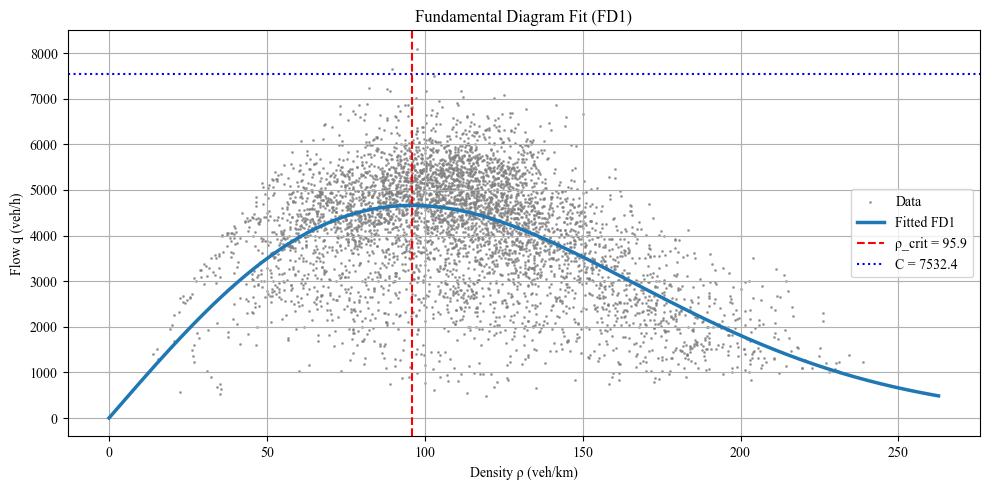

{'rho_crit': 95.9072358965239,
 'V_free': 79.95155675279663,
 'a': 2.0085212086558166,
 'C': 7532.372340000019,
 'Q_fd1': <function traffic_flow.solvers.calibration.fit_fd1.<locals>.Q_fd1(rho)>}

In [3]:
DATE = "11_28"

scenario = load_scenario("i24", DATE)
spec, traffic = scenario.spec, scenario.traffic

print("on_ramps:\t", scenario.spec.on_ramps.astype(int))
print("off_ramps:\t", scenario.spec.off_ramps.astype(int))

p_hat = scenario.traffic.density * scenario.spec.lanes
q_hat = scenario.traffic.flow
v_hat = q_hat / p_hat

fit_fd1(p_hat.ravel(), q_hat.ravel())

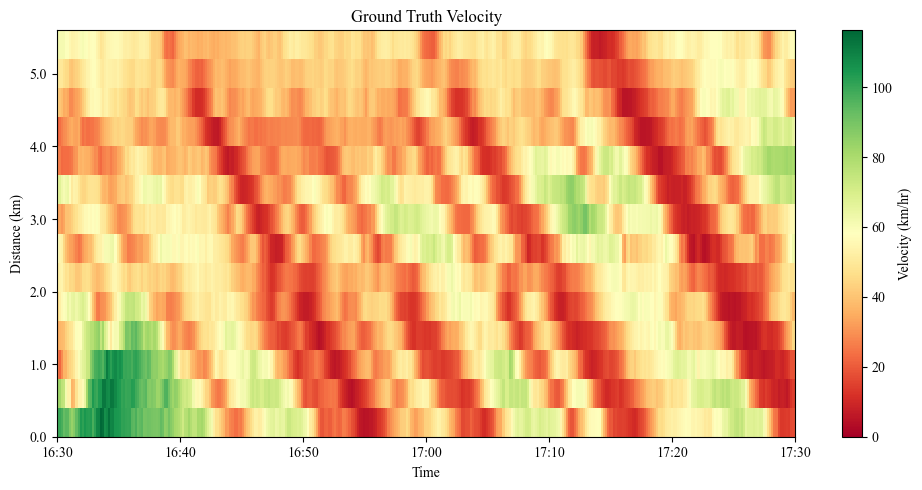

In [4]:
p = Plotter(1, 1)
p[0].plot_time_space(traffic.velocity, spec, vmax=float(traffic.velocity.max()),
    title="Ground Truth Velocity", colorbar=("v", "Velocity (km/hr)"))
p.show()

In [5]:
random.seed(1)
np.random.seed(1)

calibration_config = CalibrationConfig(include_ramping=True)

start = time.time()
params = calibrate(scenario, calibration_config)
print(f"Calibration took {time.time() - start:.2f} seconds")

seg 0 is not an off-ramp, fixing beta to 1e-3
seg 1 is not an off-ramp, fixing beta to 1e-3
seg 2 is not an off-ramp, fixing beta to 1e-3
seg 3 is not an off-ramp, fixing beta to 1e-3
seg 4 is not an off-ramp, fixing beta to 1e-3
seg 5 is not an off-ramp, fixing beta to 1e-3
seg 6 is not an off-ramp, fixing beta to 1e-3
seg 7 is not an off-ramp, fixing beta to 1e-3
seg 8 is not an off-ramp, fixing beta to 1e-3
seg 10 is not an off-ramp, fixing beta to 1e-3
seg 12 is not an off-ramp, fixing beta to 1e-3
seg 13 is not an off-ramp, fixing beta to 1e-3
Ipopt 3.14.20: max_iter=20000
acceptable_constr_viol_tol=1e-12
constr_viol_tol=1e-12


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
****************************************************

In [6]:
simulation = simulate(scenario, params, real_data=True)
assert simulation.density[:-1].shape == traffic.density.shape

In [51]:
# np.save(RESULTS_DIR/"upstream_flow.npy", smooth_inflow(q_hat[:, 0]) if smoothing else q_hat[:, 0])
# np.save(RESULTS_DIR/"downstream_density.npy", smooth_inflow(p_hat[:, -1]) if smoothing else p_hat[:, -1])

In [7]:
comparisons: dict[str, tuple[time_space, time_space, str]] = {
    "Velocity": (traffic.velocity, simulation.velocity[:-1], "km/hr"),
    "Density": (traffic.density * spec.lanes, simulation.density[:-1] * spec.lanes, "veh/km"),
    "Flow": (traffic.flow, simulation.flow_per_lane[:-1] * spec.lanes, "veh/hr")
}

In [53]:
# # Save everything
# tau_array = results["tau"]
# K_array = results["K"]
# eta_high_array = results["eta_high"]
# rho_crit_array = results["rho_crit"]
# v_free_array = results["v_free"]
# a_array = results["a"]
# num_lanes_array = results["num_lanes"]
# # if include_ramping:
#     # gamma_array = results["gamma"]
# beta_array = results["beta"]
# r_inflow_array = results["r_inflow"]
# v_pred_array = results["v_pred"]
# rho_pred_array = results["rho_pred"]
# q_array = v_pred_array * rho_pred_array

# np.save(f"{RESULTS_DIR}/tau.npy", tau_array)
# np.save(f"{RESULTS_DIR}/K.npy", K_array)
# np.save(f"{RESULTS_DIR}/eta_high.npy", eta_high_array)
# np.save(f"{RESULTS_DIR}/rho_crit.npy", rho_crit_array)
# np.save(f"{RESULTS_DIR}/v_free.npy", v_free_array)
# np.save(f"{RESULTS_DIR}/a.npy", a_array)
# np.save(f"{RESULTS_DIR}/num_lanes.npy", num_lanes_array)
# np.save(f"{RESULTS_DIR}/q_pred.npy", q_array)
# np.save(f"{RESULTS_DIR}/v_pred.npy", v_pred_array)
# np.save(f"{RESULTS_DIR}/rho_pred.npy", rho_pred_array)
# # np.save("r_array.npy", r_array)
# # if include_ramping:
#     # np.save("gamma_array.npy", gamma_array)
# np.save(f"{RESULTS_DIR}/beta_array.npy", beta_array)
# np.save(f"{RESULTS_DIR}/r_inflow_array.npy", r_inflow_array)

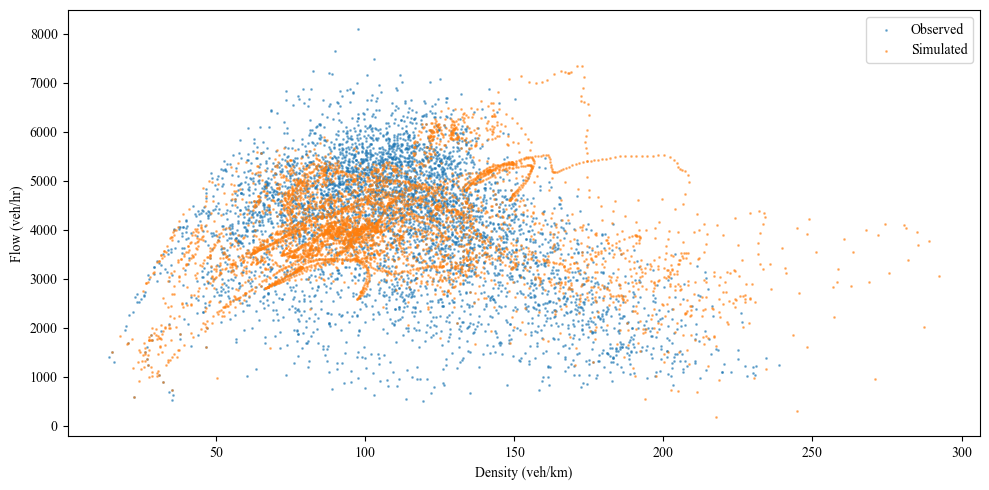

In [9]:
p = Plotter(1, 1)
for rho, flow, label in zip(comparisons["Density"][:2], comparisons["Flow"][:2], ("Observed", "Simulated")):
    p[0].scatter(rho.ravel(), flow.ravel(), label=label, s=1, alpha=0.5)
p[0].set(xlabel="Density (veh/km)", ylabel="Flow (veh/hr)")
p.show()

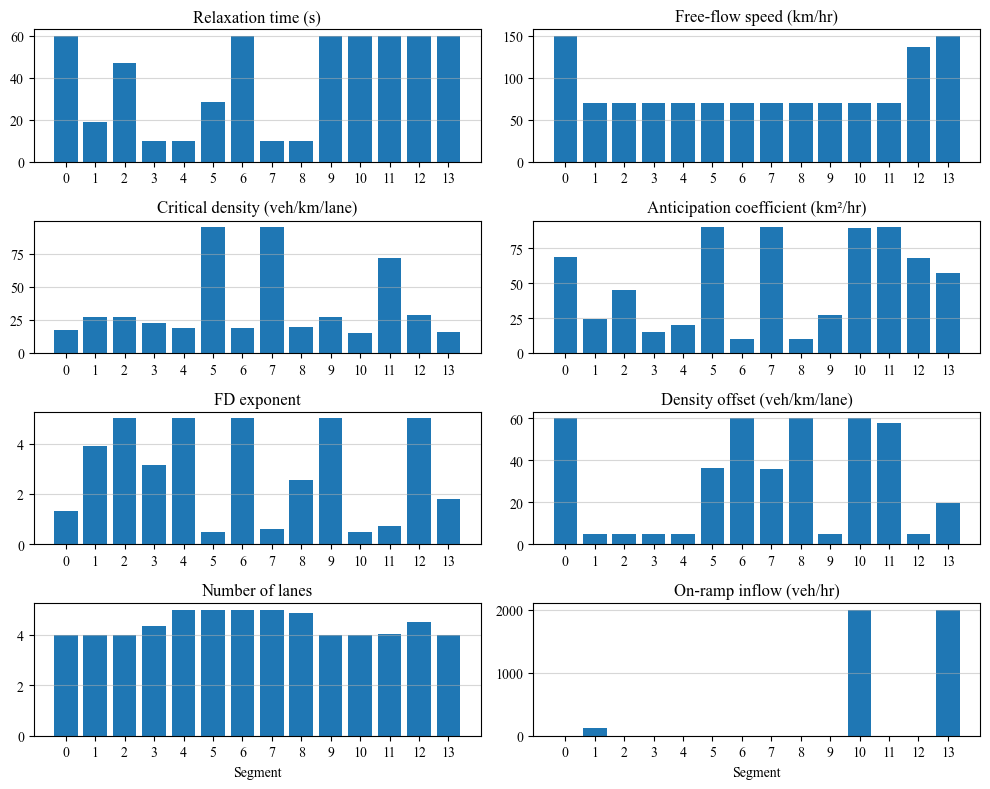

In [18]:
parameter_plots = {
    "Relaxation time (s)": params["tau"] * 3600,
    "Free-flow speed (km/hr)": params["v_free"],
    "Critical density (veh/km/lane)": params["p_crit"],
    "Anticipation coefficient (km²/hr)": params["eta_high"],
    "FD exponent": params["a"],
    "Density offset (veh/km/lane)": params["K"],
    "Number of lanes": spec.lanes,
}
if calibration_config.include_ramping:
    parameter_plots["On-ramp inflow (veh/hr)"] = params["r"]

p = Plotter(len(parameter_plots)//2, 2, figsize=(10, len(parameter_plots)))

for ax, (label, values) in zip(p, parameter_plots.items()):
    ax.bar(range(spec.num_segments), values)
    ax.set(title=label, xticks=range(spec.num_segments))
    ax.grid(axis="y", alpha=0.5)
for ax in [p[6], p[7]]: ax.set(xlabel="Segment")

p.show()

In [20]:
from traffic_flow.results.analysis import mape, rmse
from traffic_flow.console import print_table

print_table(headers=["Quantity", "MAPE", "RMSE"], data=[
    [name, f"{mape(observed, predicted):.2f} %", f"{rmse(observed, predicted):.2f} {unit}"]
    for name, (observed, predicted, unit) in comparisons.items()
])

+------------+---------+----------------+
| Quantity   | MAPE    | RMSE           |
+============+=========+================+
| Velocity   | 34.51 % | 13.03 km/hr    |
| Density    | 24.86 % | 34.26 veh/km   |
| Flow       | 30.61 % | 1204.48 veh/hr |
+------------+---------+----------------+


In [59]:
# np.save(f"{RESULTS_DIR}/v_sim.npy", v_sim)

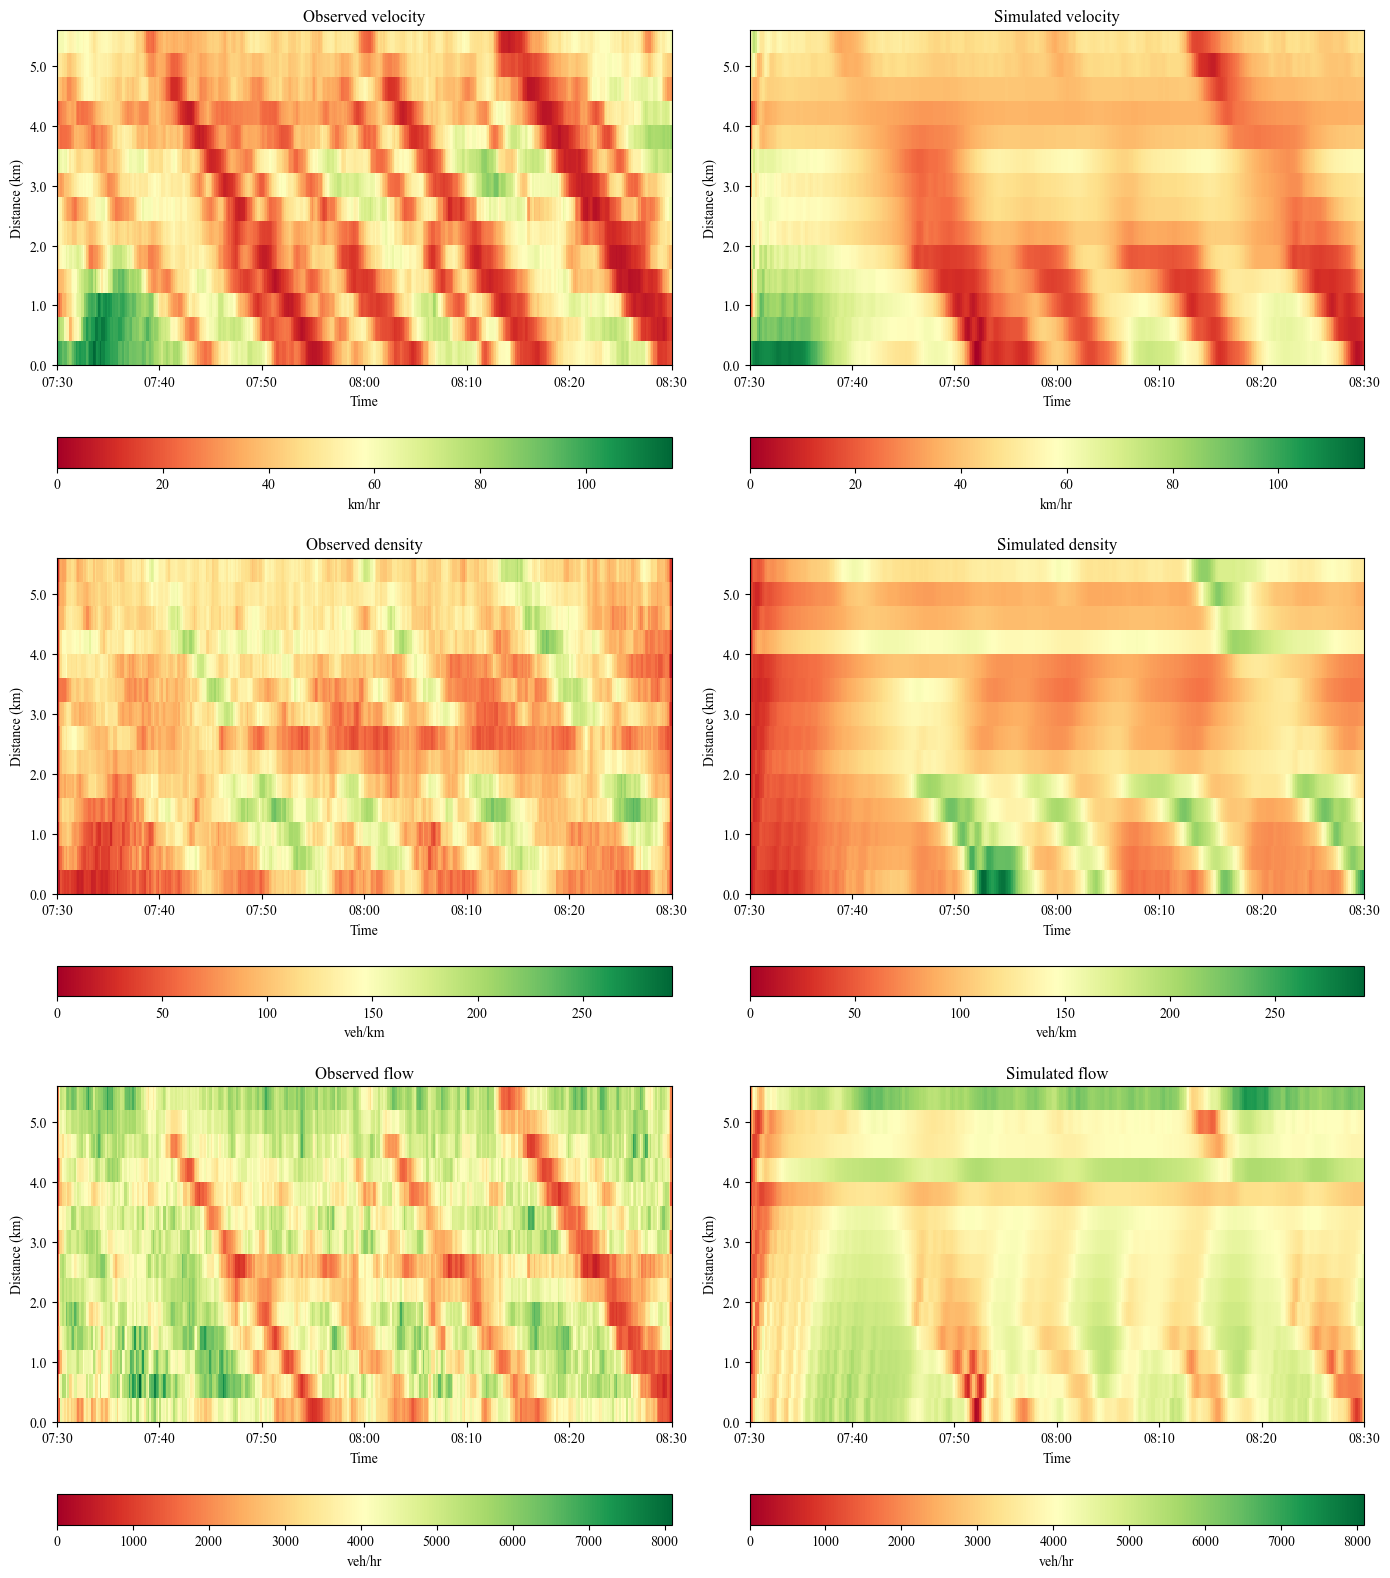

In [ ]:
p = Plotter(3, 2, figsize=(14, 16))

for row, (name, (observed, predicted, unit)) in enumerate(comparisons.items()):
    vmax = float(max(observed.max(), predicted.max()))
    for col, (label, values) in enumerate([("Observed", observed), ("Simulated", predicted)]):
        p[row, col].plot_time_space(values, spec, vmax, title=f"{label} {name.lower()}", colorbar=("h", unit), cmap="RdYlGn")

p.show()

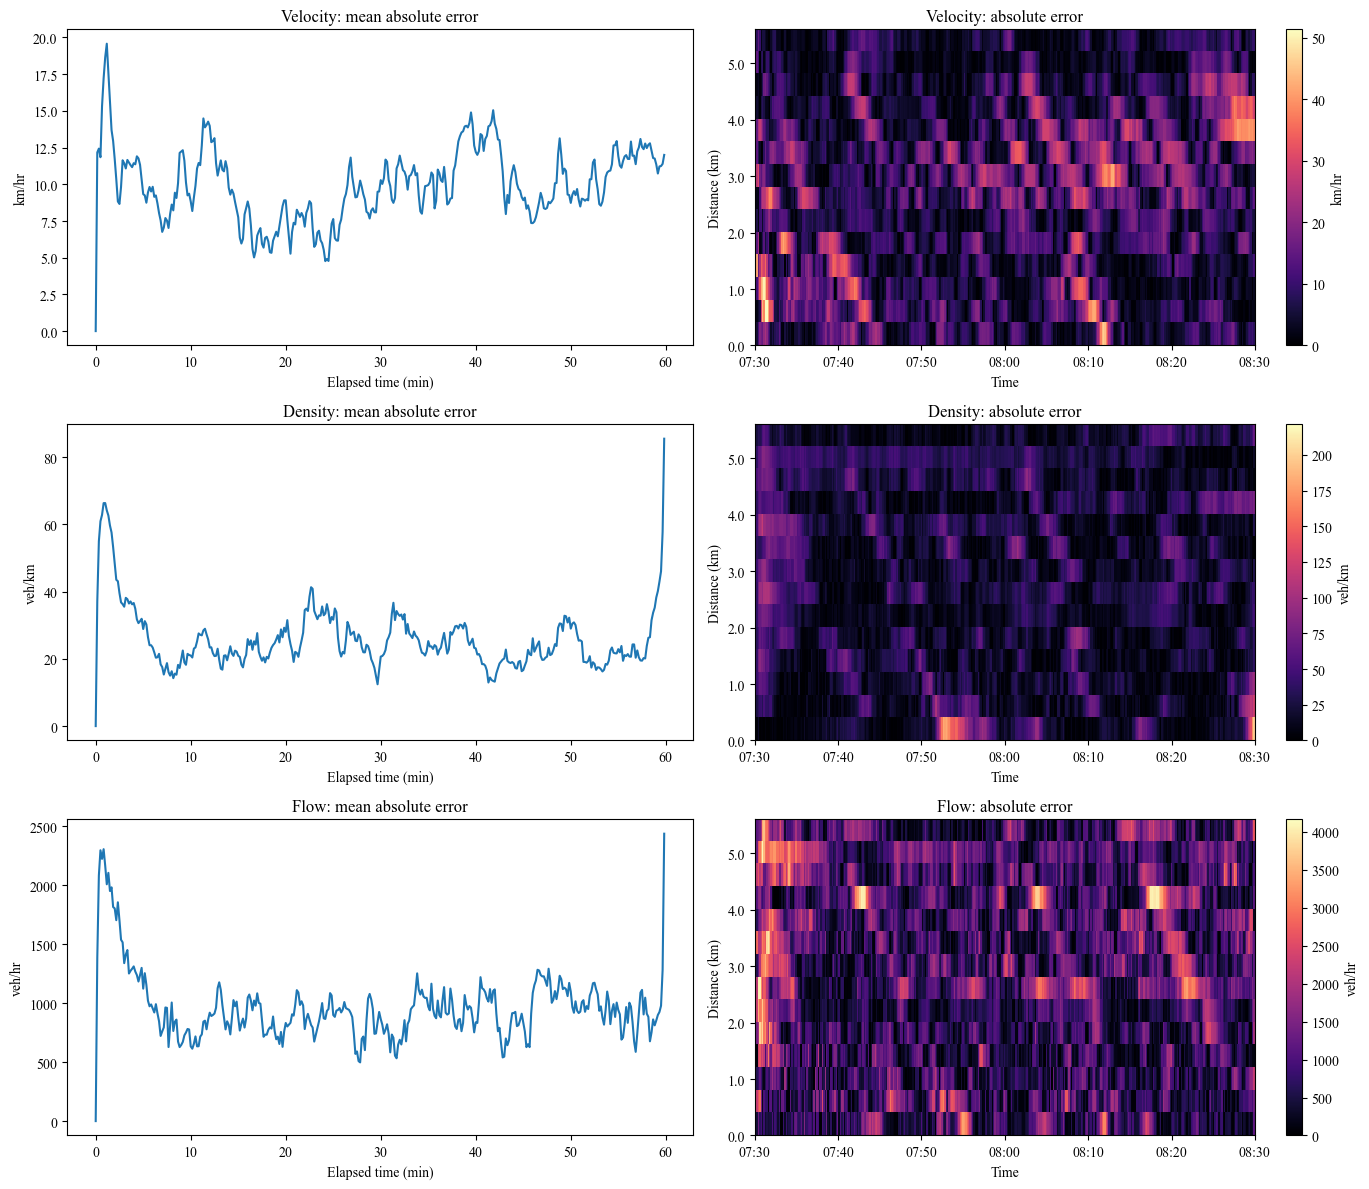

In [ ]:
p = Plotter(3, 2, figsize=(14, 12))

for row, (name, (observed, predicted, unit)) in enumerate(comparisons.items()):
    error = np.abs(observed - predicted)
    minutes = np.arange(len(error)) * spec.time_step * 60

    p[row, 0].plot(minutes, error.mean(axis=1))
    p[row, 0].set(title=f"{name}: mean absolute error", xlabel="Elapsed time (min)", ylabel=unit)

    p[row, 1].plot_time_space(error, spec, vmax=float(error.max()) or 1.0,
        title=f"{name}: absolute error", colorbar=("v", unit), cmap="magma")

p.show()

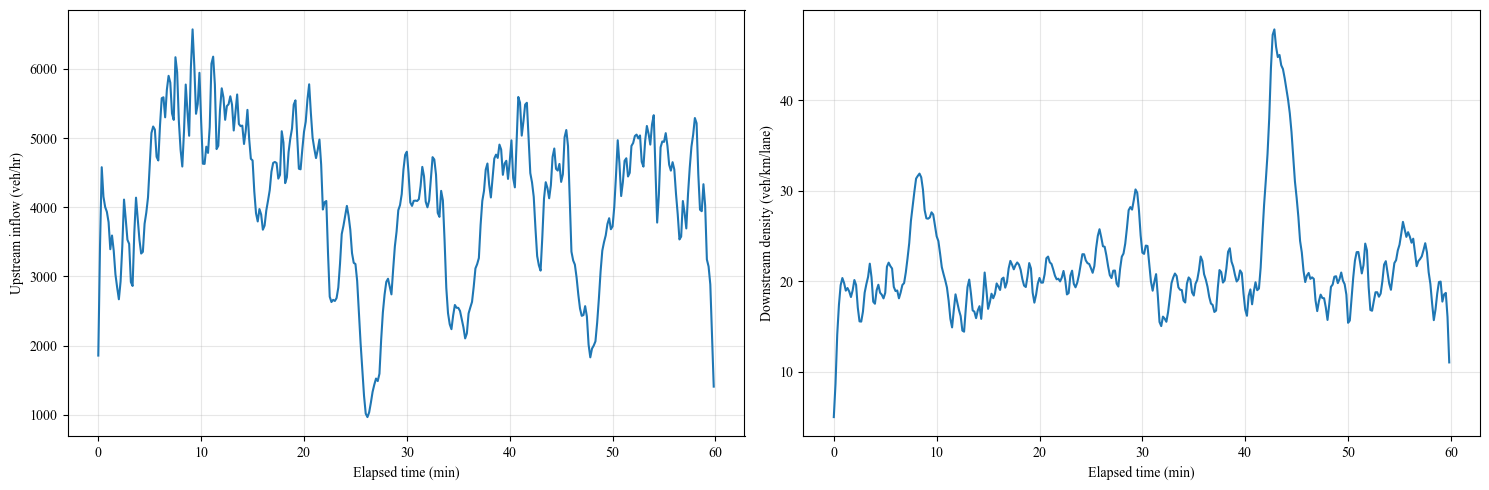

In [ ]:
boundaries = {
    "Upstream inflow (veh/hr)": traffic.inflow,
    "Downstream density (veh/km/lane)": traffic.downstream_density,
}

p = Plotter(1, 2)

for ax, (label, values) in zip(p, boundaries.items()):
    minutes = np.arange(len(values)) * spec.time_step * 60
    ax.plot(minutes, values)
    ax.set(xlabel="Elapsed time (min)", ylabel=label)

p.show()

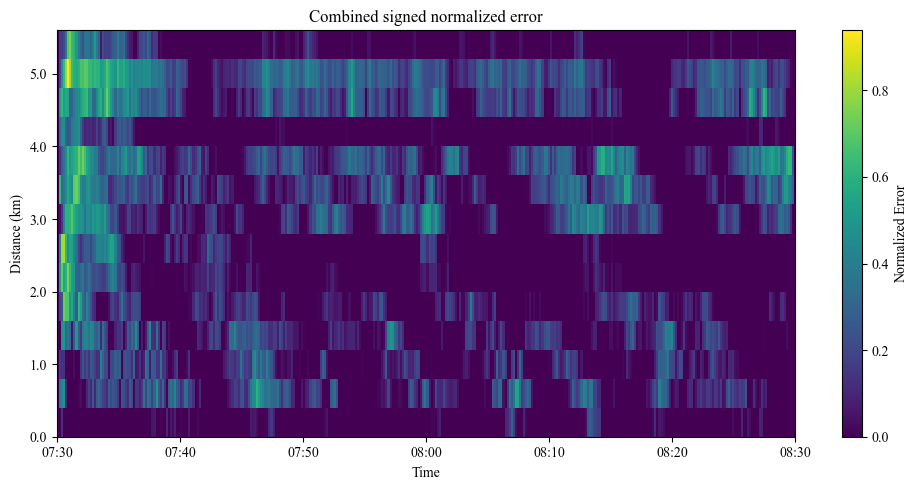

In [27]:
diff = sum(((observed - predicted) / observed.max() for observed, predicted, _ in comparisons.values()), np.array(0))

p = Plotter(1, 1)
p[0].plot_time_space(diff, spec, vmax=float(diff.max()) or 1.0,
    title="Combined signed normalized error", colorbar=("v", "Normalized Error"), cmap="viridis")
p.show()